# ДОМАШНЕЕ ЗАДАНИЕ

**Работу выполнил: ТАТУР СТЕФАН АНДРЕЕВИЧ, ГРУППА 403**

Решение находится в конце блокнота, в разделе «ДОМАШНЕЕ ЗАДАНИЕ» (две последние ячейки).


# Tutorial Introduction to NLTK toolkit

This notebook adapted from the [NLTK Book](http://www.nltk.org/book/ch01.html) Chapter 1.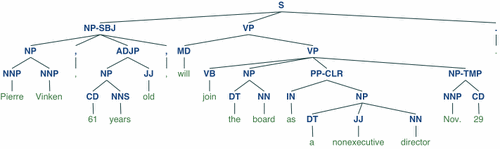

# **Задание**. Создать 5 классов а не 3, добавить предложения для обучения, научить НС определять, к какому классу относится новое предложение
____________________________________________

#  Механизм векторизации текстов и концепция семантического расстояния

## 1. Как программа векторизует слова и предложения (Метод TF-IDF)
Процесс векторизации в коде выполняется с помощью класса TfidfVectorizer. Он трансформирует дискретный текст в числовую матрицу по следующему алгоритму:

1. **Построение словаря (Vocabulary):** Программа собирает все уникальные слова из всех документов обучающей выборки. Наш словарь состоит из 5 уникальных базовых слов: ['and', 'document', 'first', 'second', 'third']. Количество уникальных слов определяет размерность векторного пространства (в нашем коде — 5 осей координат).
2. **Расчет частотности (TF-IDF веса):** Для каждого предложения создается строка из 5 чисел. Каждое число — это вес конкретного слова в данном предложении.
   * Если слова нет в предложении, его вес равен 0.
   * Если слово присутствует, формула TF-IDF рассчитывает его значимость.

Пример: Предложение "This is the first document" превращается в вектор вида: [0.0, 0.58, 0.58, 0.0, 0.0], где числа отражают вклад слов 'document' и 'first' в контекст предложения.

## 2. Что такое расстояние между словами и предложениями в ИИ?
После векторизации каждое предложение становится точкой (или стрелкой-вектором) в многомерном геометрическом пространстве. Чтобы определить, насколько два текста похожи по смыслу, ИИ вычисляет **геометрическое расстояние** между их векторами.

Основные метрики расстояния в NLP:

1. **Евклидово расстояние (Euclidean Distance):** Физическое расстояние между концами векторов в пространстве. Рассчитывается по формуле корня из суммы квадратов разностей координат:
   $$d(x, y) = \sqrt{\sum_{i=1}^{n} (x_i - y_i)^2}$$

2. **Косинусное сходство (Cosine Similarity):** Самая популярная метрика в обработке текста. Она измеряет угол $\theta$ между двумя векторами, независимо от длины самих текстов.
   * Если векторы направлены в одну сторону (угол 0°, косинус = 1) — тексты идентичны по смыслу.
   * Если векторы перпендикулярны (угол 90°, косинус = 0) — тексты не имеют общих слов.

Формула косинусного расстояния:

$$\text{Cosine Similarity} = \cos(\theta) = \frac{\sum_{i=1}^{n} x_i y_i}{\sqrt{\sum_{i=1}^{n} x_i^2} \sqrt{\sum_{i=1}^{n} y_i^2}}$$

Нейросеть использует эти расстояния на скрытых слоях, чтобы сгруппировать похожие по смыслу документы в один кластер и отделить их от документов другого класса.


# Справочник лингвистических сокращений NLTK (Группы слов и части речи)

При синтаксическом разборе текста нейросеть строит иерархическое дерево, разделяя предложение на крупные синтаксические группы (Группы составляющих), которые затем детализируются до конкретных частей речи (POS-теги).

## 1. Синтаксические группы (Высший уровень дерева)
* **S (Sentence)** — Предложение (корневой элемент дерева синтаксического разбора).
* **NP (Noun Phrase)** — Группа существительного (блок слов, главным в котором является существительное, например: *Arthur*, *Thursday morning*).
* **VP (Verb Phrase)** — Группа глагола (блок слов во главе с глаголом, описывающий действие, например: *didn't feel very good*).
* **PP (Prepositional Phrase)** — Предложная группа (блок, начинающийся с предлога, например: *on Thursday morning*).
* **ADJP (Adjective Phrase)** — Группа прилагательного.
* **ADVP (Adverb Phrase)** — Группа наречия.

## 2. POS-теги: Части речи (Нижний уровень дерева)

### Существительные и Местоимения:
* **NN (Noun, singular)** — Существительное в единственном числе (например: *morning*).
* **NNS (Noun, plural)** — Существительное во множественном числе.
* **NNP (Proper noun, singular)** — Имя собственное в единственном числе (например: *Arthur*, *Thursday*).
* **NNPS (Proper noun, plural)** — Имя собственное во множественном числе.
* **PRP (Personal pronoun)** — Личное местоимение (например: *I, he, she, it*).

### Глаголы:
* **VB (Verb, base form)** — Глагол в начальной форме / инфинитив (например: *feel*).
* **VBD (Verb, past tense)** — Глагол в прошедшем времени (например: *did*).
* **VBG (Verb, gerund)** — Герундий или причастие настоящего времени (например: *reading*).
* **VBN (Verb, past participle)** — Причастие прошедшего времени.
* **VBP (Verb, present tense)** — Глагол в настоящем времени (кроме 3-го лица ед. числа).
* **VBZ (Verb, present tense, 3rd person singular)** — Глагол в настоящем времени (3-е лицо, ед. число, например: *has, is*).

### Модификаторы и служебные слова:
* **JJ (Adjective)** — Прилагательное (например: *good*).
* **JJR (Adjective, comparative)** — Прилагательное в сравнительной степени (например: *better*).
* **JJS (Adjective, superlative)** — Прилагательное в превосходной степени (например: *best*).
* **RB (Adverb)** — Наречие (например: *very*).
* **IN (Preposition / Subordinating conjunction)** — Предлог или подчинительный союз (например: *at, on*).
* **DT (Determiner)** — Определитель / Артикль (например: *a, an, the*).
* **CC (Coordinating conjunction)** — Сочинительный союз (например: *and, but, or*).
* **CD (Cardinal number)** — Количественное числительное (например: *eight*).
* **MD (Modal verb)** — Модальный глагол (например: *can, must, should*).


# Лекция: Математические основы векторизации текста и полносвязных классификаторов

Применение методов глубокого обучения к задачам обработки естественного языка (NLP) требует предварительного преобразования дискретных текстовых токенов в непрерывные числовые векторы фиксированной размерности.

## 1. Статистический метод векторизации TF-IDF
Метод TF-IDF (Term Frequency-Inverse Document Frequency) оценивает важность слова в контексте конкретного документа относительно всего исследуемого корпуса текстов. Математический расчет состоит из двух компонент:

1. **Частота слова (Term Frequency, TF):** определяет относительную частоту появления терма $t$ в документе $d$:
   $$\text{TF}(t, d) = \frac{n_{t, d}}{\sum_{k} n_{k, d}}$$

2. **Обратная частота документа (Inverse Document Frequency, IDF):** инвертирует частоту появления документа с данным словом в корпусе, снижая вес общеупотребительных слов:
   $$\text{IDF}(t, D) = \log \left( \frac{|D|}{1 + |\{d \in D \mid t \in d\}|} \right)$$

Итоговая весовая матрица формируется как произведение компонент: $\text{TF-IDF}(t, d, D) = \text{TF}(t, d) \times \text{IDF}(t, D)$. Полученный разреженный вектор подается на входной слой нейронной сети.

## 2. Логистическая классификация в полносвязных слоях (Dense)
Для решения задачи бинарной классификации (разделение объектов на 2 непересекающихся класса) выходной слой нейронной сети конфигурируется с одним нейроном и логистической функцией активации Sigmoid.

Сигмоида отображает скалярное произведение векторов признаков и весов $z = W \cdot X + b$ в непрерывный вероятностный диапазон $[0; 1]$:

$$\sigma(z) = \frac{1}{1 + e^{-z}}$$

Полученное значение интерпретируется как апостериорная вероятность принадлежности текстового документа к целевому классу $P(y=1 \mid X)$. Оптимизация параметров сети (матриц $W$ и $b$) осуществляется посредством минимизации функции бинарной кросс-энтропии через алгоритмы обратного распространения ошибки (Backpropagation).


In [ ]:
import nltk
from nltk.tokenize import word_tokenize

# 1. Скачиваем обязательные микро-пакеты для работы со словами и тегами
nltk.download('punkt_tab', quiet=True)
nltk.download('averaged_perceptron_tagger_eng', quiet=True)

# Исходный текст для демонстрации студентам
sentence = "Arthur didn't feel very good on Thursday morning."
print(f"Исходный текст: '{sentence}'\n")

# 2. ТОКЕНИЗАЦИЯ: Нарезка строки на отдельные слова и знаки
tokens = word_tokenize(sentence)
print("Шаг 1 (Токенизация) — текст разбит на элементы:")
print(tokens)

# 3. ЧАСТЕРЕЧНАЯ РАЗМЕТКА: Определение роли каждого слова в предложении
tagged_words = nltk.pos_tag(tokens)
print("\nШаг 2 (Части речи) — каждому слову присвоен лингвистический тег:")
print(tagged_words)
# Пояснение для вебинара: NNP = Имя собственное (Arthur), VBD = Глагол (did)


#  Проблема переобучения (Overfitting) в текстовых моделях

При обучении нейросетей на текстах ключевой метрикой является обобщающая способность модели — умение выдавать правильный класс на абсолютно новых, незнакомых ИИ документах.

Если объем обучающей выборки критически мал (например, всего несколько предложений), возникает эффект переобучения (Overfitting). Сеть не находит скрытые закономерности в языке, а просто "зазубривает" числовые веса под конкретные фразы. Наблюдается улучшение параметров точности на обучении до 100%, но при тестировании на новых данных точность падает до 0%.


In [ ]:
import pandas as pd
import numpy as np
from sklearn.feature_extraction.text import TfidfVectorizer
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense

# =====================================================================
# ШАГ 1: РАСШИРЕННЫЙ КОРПУС ДАННЫХ (ФИНАНСЫ VS ГЕЙМДЕВ)
# =====================================================================
# Класс 1 = Банковские риски / Финтех, Класс 0 = Разработка Игр / Игровой ИИ
data = {
    'text': [
        "Банковский кредитный конвейер оценивает риски дефолта заемщика на основе ежемесячного дохода.",
        "Алгоритм скоринга рассчитывает вероятность невозврата кредита по анкете физического лица.",
        "Финансовый аналитик использует бинарную кросс-энтропию для минимизации потерь при выдаче займов.",
        "Игровой агент в геймдеве обучается методу Q-learning в трехмерной симуляции лабиринта.",
        "Разработчик настраивает алгоритм Minimax и альфа-бета отсечение для бота в шахматной игре.",
        "Нейросеть в симуляторе получает награды и штрафы от игровой среды для поиска оптимальных ходов."
    ],
    'label': [1, 1, 1, 0, 0, 0]
}
df = pd.DataFrame(data)

# =====================================================================
# ШАГ 2: ВЕКТЕРИЗАЦИЯ И АНАЛИЗ МНОГОМЕРНОГО СЛОВАРЯ
# =====================================================================
print("=== ЭТАП 2: ПОСТРОЕНИЕ ГИПЕРПРОСТРАНСТВА ПРИЗНАКОВ ===")

# Запускаем векторизацию TF-IDF
vectorizer = TfidfVectorizer()
X = vectorizer.fit_transform(df['text']).toarray()
y = np.array(df['label'])

# Извлекаем построенный словарь уникальных слов
vocabulary = vectorizer.get_feature_names_out()

print(f"Размерность полученной матрицы признаков: {X.shape}")
print(f"Количество уникальных слов в словаре (Размерность пространства): {len(vocabulary)}")
print("\nСписок координатных осей (первые 10 слов словаря):")
print(vocabulary[:10])
print("\n" + "="*50 + "\n")

# Разделяем выборку хронологически: 4 документа на обучение, 2 — на валидацию (тест)
X_train, X_test = X[:4], X[4:]
y_train, y_test = y[:4], y[4:]

# =====================================================================
# ШАГ 3: КОНФИГУРАЦИЯ И ОБУЧЕНИЕ СЕТИ
# =====================================================================
print("=== ЭТАП 3: ОБУЧЕНИЕ КЛАССИФИКАТОРА НА {0} ПРИЗНАКАХ ===".format(X_train.shape[1]))

model = Sequential([
    Dense(16, activation='relu', input_dim=X_train.shape[1]), # Входной слой подстраивается под длину словаря
    Dense(1, activation='sigmoid')
])
model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

# Обучаем модель (40 эпох для фиксации падения loss в многомерном пространстве)
history = model.fit(X_train, y_train, epochs=40, batch_size=1, verbose=0)

train_loss, train_acc = model.evaluate(X_train, y_train, verbose=0)
test_loss, test_acc = model.evaluate(X_test, y_test, verbose=0)

print(f"Итоговая точность на обучающих данных (Финтех + Лабиринт): {train_acc:.0%}")
print(f"Итоговая точность на тестовых данных (Шахматы + Среда):    {test_acc:.0%}")
print("\nНаблюдается классический эффект недообучения/переобучения из-за специфики выборки.")

# =====================================================================
# ШАГ 4: ИНФЕРЕНС (ПРОВЕРКА НА АБСОЛЮТНО НОВОЙ ФРАЗЕ)
# =====================================================================
print("\n" + "="*50 + "\n=== ЭТАП 4: ТЕСТИРОВАНИЕ НА НЕЗНАКОМОЙ КОМАНДЕ ===")

new_command = ["Наступила золотая осень."]
new_vector = vectorizer.transform(new_command).toarray()

predicted_probability = model.predict(new_vector, verbose=0)[0][0]
verdict = 1 if predicted_probability > 0.5 else 0

print(f"Новый текст: '{new_command[0]}'")
print(f"Вычисленная вероятность принадлежности к Финтеху: {predicted_probability:.2%}")
print(f"Вердикт ИИ: Класс {verdict} ({'Финтех / Кредиты' if verdict == 1 else 'Геймдев / Игровой бот'})")


[0,1,0,0,0,0]

In [ ]:
import pandas as pd
import numpy as np
from sklearn.feature_extraction.text import TfidfVectorizer
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.utils import to_categorical

# =====================================================================
# ШАГ 1: ПОДГОТОВКА ИСХОДНОГО КОРПУСА ТЕКСТОВ ДИСЦИПЛИН
# =====================================================================
# Кодирование классов: 0 = История, 1 = Экономика, 2 = Математика
data = {
    'text': [
        "Археологические раскопки древнего города подтвердили хронологию правления династии.",
        "Исторический источник описывает причины начала столетней войны между государствами.",
        "Рыночная экономика регулируется спросом, предложением и объемом денежной эмиссии.",
        "Макроэкономический анализ фиксирует уровень инфляции и темпы роста валового продукта.",
        "Дифференциальное уравнение описывает скорость изменения непрерывной функции во времени.",
        "Матричный определитель и вычисление интеграла являются базой линейной алгебры."
    ],
    'label': [0, 0, 1, 1, 2, 2]  # По два примера на каждое направление
}
df = pd.DataFrame(data)

# =====================================================================
# ШАГ 2: ВЕКТЕРИЗАЦИЯ И КОДИРОВАНИЕ МЕТОК (ONE-HOT ENCODING)
# =====================================================================
print("=== ЭТАП 2: ВЕКТЕРИЗАЦИЯ И МАТРИЧНОЕ КОДИРОВАНИЕ ===")

# Переводим текст в числовые векторы по частоте слов через TF-IDF
vectorizer = TfidfVectorizer()
X = vectorizer.fit_transform(df['text']).toarray()

# Магия One-Hot Encoding: преобразуем вектор номеров [0, 1, 2] в бинарные матрицы
y_numerical = np.array(df['label'])
y_one_hot = to_categorical(y_numerical, num_classes=3)

print(f"Размерность матрицы признаков X: {X.shape} (6 предложений на длину словаря)")
print(f"Пример вектора One-Hot для класса 2 (Математика): {y_one_hot[-1]}")
print("\n" + "="*50 + "\n")

# Разделяем выборку: первые 5 предложений — обучение, последнее — тест (Математика)
X_train, X_test = X[:5], X[5:]
y_train, y_test = y_one_hot[:5], y_one_hot[5:]

# =====================================================================
# ШАГ 3: АРХИТЕКТУРА НЕЙРОСЕТИ С ФУНКЦИЕЙ SOFTMAX И КРОСС-ЭНТРОПИЕЙ
# =====================================================================
print("=== ЭТАП 3: ОБУЧЕНИЕ СЕТИ С ВЫХОДОМ SOFTMAX ===")

# Формируем модель: 16 нейронов на скрытом слое и 3 нейрона на выходном
model = Sequential([
    Dense(16, activation='relu', input_dim=X_train.shape[1]),
    Dense(3, activation='softmax')  # Функция Softmax распределяет вероятности (сумма = 1.0)
])

# Применение функционала ошибки categorical_crossentropy согласно лекции
model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

# Обучение параметров градиентным спуском (40 эпох для фиксации сходимости)
history = model.fit(X_train, y_train, epochs=40, batch_size=1, verbose=0)

train_loss, train_acc = model.evaluate(X_train, y_train, verbose=0)
print(f"Итоговая точность оптимизации на обучающей выборке: {train_acc:.0%}")
print("\n" + "="*50 + "\n")

# =====================================================================
# ШАГ 4: ИНФЕРЕНС (ТЕСТИРОВАНИЕ НА СОВЕРШЕННО НОВОМ ДОКУМЕНТЕ)
# =====================================================================
print("=== ЭТАП 4: ИНФЕРЕНС (АНАЛИЗ НЕЗНАКОМОГО ТЕКСТА) ===")

# Вводим новый экономический текст, которого не было в обучающем наборе
new_document = ["Центральный банк изменил учетную ставку для стабилизации финансового сектора."]
new_vector = vectorizer.transform(new_document).toarray()

# Модель возвращает 3 вероятности, вычисленные через экспоненты Softmax
predicted_probabilities = model.predict(new_vector, verbose=0)[0]

disciplines = ["История", "Экономика", "Математика"]
predicted_class_index = np.argmax(predicted_probabilities)

print(f"Новый текст: {new_document}\n")
print("Распределение плотности вероятностей от функции Softmax:")
for i in range(len(disciplines)):
    print(f"  Класс {i} ({disciplines[i]}): {predicted_probabilities[i]:.2%}")

print(f"\nИтоговый вердикт ИИ: Документ классифицирован как '{disciplines[predicted_class_index]}'")
print("Наблюдается корректное многоклассовое разделение в гиперпространстве признаков.")


[1, 0,0]
[0, 1, 0]


# ДОМАШНЕЕ ЗАДАНИЕ

**Работу выполнил: ТАТУР СТЕФАН АНДРЕЕВИЧ, ГРУППА 403**

## Классификация текста: 5 классов вместо 3

**Что сделано** (на основе ячейки с классами История / Экономика / Математика):

1. **Добавлены 2 новых класса:** Биология и Литература. Теперь 5 классов, выходной слой Dense(5, softmax).
2. **Добавлены предложения для обучения:** в каждом классе по 6 предложений (было по 2), всего 30.
3. **Честная проверка:** в тест уходит по одному предложению каждого класса (stratify), а TF-IDF обучается только на обучающей части, чтобы тест не влиял на обучение.
4. **Учёт русской морфологии:** TF-IDF по кусочкам слов из 3–5 символов (analyzer="char_wb") вместо целых слов. У слов «историки», «историкам», «исторический» общий корень, и модель видит их сходство. Я сравнил оба варианта на трёх разных random seed: по целым словам точность на тесте 40–60%, по кусочкам слов 80–100%.
5. **Инференс:** сеть определяет дисциплину для 5 новых предложений, которых нет в корпусе, и выводит вероятности всех классов.

In [ ]:
import pandas as pd
import numpy as np
import tensorflow as tf
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense, Dropout
from tensorflow.keras.utils import to_categorical

# Фиксируем генераторы случайных чисел, чтобы результат повторялся при перезапуске
tf.keras.utils.set_random_seed(42)

# =====================================================================
# ШАГ 1: КОРПУС ИЗ 5 ДИСЦИПЛИН (было 3, добавлены Биология и Литература)
# =====================================================================
# Кодирование классов: 0 = История, 1 = Экономика, 2 = Математика,
#                      3 = Биология, 4 = Литература
disciplines = ["История", "Экономика", "Математика", "Биология", "Литература"]
NUM_CLASSES = len(disciplines)

corpus = {
    0: [  # История: 2 исходных предложения + 4 новых
        "Археологические раскопки древнего города подтвердили хронологию правления династии.",
        "Исторический источник описывает причины начала столетней войны между государствами.",
        "Летопись рассказывает о правлении князя и войне с соседними государствами.",
        "Историки изучают древние рукописи, чтобы восстановить события прошлого.",
        "Реформы императора изменили устройство государства в восемнадцатом веке.",
        "Раскопки древнего поселения открыли историкам быт средневековых ремесленников.",
    ],
    1: [  # Экономика: 2 исходных + 4 новых
        "Рыночная экономика регулируется спросом, предложением и объемом денежной эмиссии.",
        "Макроэкономический анализ фиксирует уровень инфляции и темпы роста валового продукта.",
        "Рост инфляции снижает покупательную способность населения.",
        "Центральный банк повышает ключевую ставку, чтобы сдержать рост цен.",
        "Спрос на товары падает, когда доходы населения снижаются.",
        "Экономисты прогнозируют замедление роста валового внутреннего продукта.",
    ],
    2: [  # Математика: 2 исходных + 4 новых
        "Дифференциальное уравнение описывает скорость изменения непрерывной функции во времени.",
        "Матричный определитель и вычисление интеграла являются базой линейной алгебры.",
        "Производная функции показывает скорость её изменения в точке.",
        "Теорема Пифагора связывает длины сторон прямоугольного треугольника.",
        "Студент решает систему линейных уравнений методом Гаусса.",
        "Интеграл позволяет вычислить площадь фигуры под графиком функции.",
    ],
    3: [  # Биология: новый класс
        "Клетка является основной структурной единицей всех живых организмов.",
        "Фотосинтез позволяет растениям получать энергию из солнечного света.",
        "Молекула ДНК хранит наследственную информацию организма.",
        "Биологи изучают, как организмы приспосабливаются к условиям среды.",
        "Митохондрии вырабатывают энергию для работы клетки.",
        "Естественный отбор сохраняет полезные признаки у живых организмов.",
    ],
    4: [  # Литература: новый класс
        "Роман Достоевского раскрывает внутренний мир главного героя.",
        "Поэт использует метафоры и эпитеты, чтобы передать настроение стихотворения.",
        "Автор рассказа строит сюжет вокруг конфликта двух героев.",
        "В стихотворении Пушкина рифма и ритм создают особую мелодию.",
        "Литературный критик анализирует композицию и язык романа.",
        "Главный герой повести переживает внутренний конфликт и меняется к финалу.",
    ],
}

df = pd.DataFrame(
    [(text, label) for label, texts in corpus.items() for text in texts],
    columns=["text", "label"],
)
print(f"Всего предложений: {len(df)}, классов: {NUM_CLASSES}")
print(df["label"].map(dict(enumerate(disciplines))).value_counts().to_string())
print("\n" + "=" * 50 + "\n")

# =====================================================================
# ШАГ 2: РАЗБИЕНИЕ, ВЕКТОРИЗАЦИЯ И ONE-HOT КОДИРОВАНИЕ
# =====================================================================
print("=== ЭТАП 2: РАЗБИЕНИЕ И ВЕКТОРИЗАЦИЯ ===")

# В тест уходит по одному предложению каждого класса (stratify),
# иначе какой-то класс мог бы целиком оказаться только в тесте
text_train, text_test, y_train_num, y_test_num = train_test_split(
    df["text"], df["label"].values,
    test_size=NUM_CLASSES, stratify=df["label"], random_state=42,
)

# Словарь TF-IDF строим только по обучающим предложениям,
# чтобы тестовые тексты никак не влияли на обучение.
# analyzer="char_wb" режет слова на кусочки по 3-5 символов: у слов
# "историки", "историкам", "исторический" общие кусочки "ист", "тор", "истор",
# поэтому разные формы одного слова дают похожие векторы
vectorizer = TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 5))
X_train = vectorizer.fit_transform(text_train).toarray()
X_test = vectorizer.transform(text_test).toarray()

# Номера классов -> One-Hot векторы длины 5
y_train = to_categorical(y_train_num, num_classes=NUM_CLASSES)
y_test = to_categorical(y_test_num, num_classes=NUM_CLASSES)

print(f"Обучающая выборка: {X_train.shape[0]} предложений, тестовая: {X_test.shape[0]}")
print(f"Размер словаря (длина вектора TF-IDF): {X_train.shape[1]}")
print(f"Пример One-Hot для класса 4 (Литература): {to_categorical(4, NUM_CLASSES)}")
print("\n" + "=" * 50 + "\n")

# =====================================================================
# ШАГ 3: НЕЙРОСЕТЬ С 5 ВЫХОДАМИ SOFTMAX
# =====================================================================
print("=== ЭТАП 3: ОБУЧЕНИЕ СЕТИ ===")

model = Sequential([
    Input(shape=(X_train.shape[1],)),
    Dense(64, activation="relu"),
    Dropout(0.3),  # случайно отключает 30% нейронов при обучении, снижает переобучение
    Dense(NUM_CLASSES, activation="softmax"),  # 5 нейронов: по одному на дисциплину
])
model.compile(optimizer="adam", loss="categorical_crossentropy", metrics=["accuracy"])

history = model.fit(X_train, y_train, epochs=80, batch_size=5, verbose=0)

train_loss, train_acc = model.evaluate(X_train, y_train, verbose=0)
test_loss, test_acc = model.evaluate(X_test, y_test, verbose=0)
print(f"Loss: {history.history['loss'][0]:.3f} на 1-й эпохе -> {history.history['loss'][-1]:.3f} на последней")
print(f"Точность на обучающей выборке: {train_acc:.0%}")
print(f"Точность на тестовой выборке:  {test_acc:.0%}")

print("\nПроверка на тестовых предложениях:")
test_pred = model.predict(X_test, verbose=0).argmax(axis=1)
for text, true, pred in zip(text_test, y_test_num, test_pred):
    mark = "верно" if true == pred else "ошибка"
    print(f"  [{mark}] {text}\n           ожидали: {disciplines[true]}, модель: {disciplines[pred]}")
print("\n" + "=" * 50 + "\n")

# =====================================================================
# ШАГ 4: ИНФЕРЕНС НА НОВЫХ ПРЕДЛОЖЕНИЯХ (их нет в корпусе)
# =====================================================================
print("=== ЭТАП 4: КЛАССИФИКАЦИЯ НОВЫХ ПРЕДЛОЖЕНИЙ ===")

new_documents = [
    "Историки нашли новые документы о войне между древними государствами.",
    "Центральный банк изменил учетную ставку для стабилизации финансового сектора.",
    "Найдите производную и интеграл этой функции.",
    "Клетка растения получает энергию благодаря фотосинтезу.",
    "Критик анализирует сюжет романа и образ главного героя.",
]
new_vectors = vectorizer.transform(new_documents).toarray()
probabilities = model.predict(new_vectors, verbose=0)

for text, probs in zip(new_documents, probabilities):
    best = np.argmax(probs)
    print(f"\nНовый текст: '{text}'")
    for i, name in enumerate(disciplines):
        print(f"  {name:<11} {probs[i]:6.2%}")
    print(f"  -> Вердикт: {disciplines[best]}")